In [ ]:
import pandas as pd
!pip install scikit-learn-extra
# kmediods
from sklearn_extra.cluster import KMedoids


In [ ]:
df=pd.read_csv("/content/sales_data (1).csv")
df

,Order_ID,Order_Date,Customer_ID,Region,City,Segment,Channel,Category,Subcategory,Product_ID,...,Discount,Sales_INR,Discount_Amount_INR,Net_Sales_INR,Cost_INR,Profit_INR,Shipping_Days,Returned,Customer_Satisfaction,Payment_Method
0,ORD111444,2024-01-01,CUST10128,West,Pune,Corporate,Online,Home & Kitchen,Appliances,P1046,...,0.00,654.30,0.00,654.30,387.43,266.87,1,No,4,Debit Card
1,ORD102034,2024-01-01,CUST10316,West,Ahmedabad,Corporate,Online,Beauty,Personal Care,P1048,...,0.10,1711.99,171.20,1540.79,874.52,666.27,6,No,3,UPI
2,ORD106623,2024-01-01,CUST11764,South,Chennai,Consumer,Online,Home & Kitchen,Cookware,P1066,...,0.05,5904.75,295.24,5609.51,3095.78,2513.74,3,No,3,Net Banking
3,ORD113951,2024-01-01,CUST12447,Central,Raipur,Consumer,Online,Home & Kitchen,Decor,P1057,...,0.15,1406.48,210.97,1195.51,720.77,474.74,4,No,3,Net Banking
4,ORD105177,2024-01-01,CUST10691,North,Chandigarh,Consumer,Online,Home & Kitchen,Decor,P1023,...,0.15,1522.20,228.33,1293.87,820.70,473.17,6,No,3,Credit Card
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14995,ORD109942,2025-12-31,CUST10397,West,Pune,Consumer,Online,Beauty,Skincare,P1004,...,0.20,14813.34,2962.67,11850.67,5930.88,4262.25,4,Yes,3,Debit Card
14996,ORD101325,2025-12-31,CUST11524,South,Bengaluru,Consumer,Retail Store,Technology,Accessories,P1013,...,0.00,2853.60,0.00,2853.60,1985.23,868.37,5,No,3,Debit Card
14997,ORD107747,2025-12-31,CUST11321,East,Guwahati,Consumer,Online,Furniture,Chairs,P1022,...,0.00,2749.28,0.00,2749.28,1795.97,953.31,2,No,3,Net Banking
14998,ORD105862,2025-12-31,CUST11426,East,Guwahati,Consumer,Online,Beauty,Personal Care,P1004,...,0.25,10019.80,2504.95,7514.85,4022.03,3492.82,8,No,3,Credit Card


In [ ]:
df.head()

,Order_ID,Order_Date,Customer_ID,Region,City,Segment,Channel,Category,Subcategory,Product_ID,...,Discount,Sales_INR,Discount_Amount_INR,Net_Sales_INR,Cost_INR,Profit_INR,Shipping_Days,Returned,Customer_Satisfaction,Payment_Method
0,ORD111444,2024-01-01,CUST10128,West,Pune,Corporate,Online,Home & Kitchen,Appliances,P1046,...,0.00,654.30,0.00,654.30,387.43,266.87,1,No,4,Debit Card
1,ORD102034,2024-01-01,CUST10316,West,Ahmedabad,Corporate,Online,Beauty,Personal Care,P1048,...,0.10,1711.99,171.20,1540.79,874.52,666.27,6,No,3,UPI
2,ORD106623,2024-01-01,CUST11764,South,Chennai,Consumer,Online,Home & Kitchen,Cookware,P1066,...,0.05,5904.75,295.24,5609.51,3095.78,2513.74,3,No,3,Net Banking
3,ORD113951,2024-01-01,CUST12447,Central,Raipur,Consumer,Online,Home & Kitchen,Decor,P1057,...,0.15,1406.48,210.97,1195.51,720.77,474.74,4,No,3,Net Banking
4,ORD105177,2024-01-01,CUST10691,North,Chandigarh,Consumer,Online,Home & Kitchen,Decor,P1023,...,0.15,1522.20,228.33,1293.87,820.70,473.17,6,No,3,Credit Card


In [ ]:
df.tail()

,Order_ID,Order_Date,Customer_ID,Region,City,Segment,Channel,Category,Subcategory,Product_ID,...,Discount,Sales_INR,Discount_Amount_INR,Net_Sales_INR,Cost_INR,Profit_INR,Shipping_Days,Returned,Customer_Satisfaction,Payment_Method
14995,ORD109942,2025-12-31,CUST10397,West,Pune,Consumer,Online,Beauty,Skincare,P1004,...,0.20,14813.34,2962.67,11850.67,5930.88,4262.25,4,Yes,3,Debit Card
14996,ORD101325,2025-12-31,CUST11524,South,Bengaluru,Consumer,Retail Store,Technology,Accessories,P1013,...,0.00,2853.60,0.00,2853.60,1985.23,868.37,5,No,3,Debit Card
14997,ORD107747,2025-12-31,CUST11321,East,Guwahati,Consumer,Online,Furniture,Chairs,P1022,...,0.00,2749.28,0.00,2749.28,1795.97,953.31,2,No,3,Net Banking
14998,ORD105862,2025-12-31,CUST11426,East,Guwahati,Consumer,Online,Beauty,Personal Care,P1004,...,0.25,10019.80,2504.95,7514.85,4022.03,3492.82,8,No,3,Credit Card
14999,ORD102445,2025-12-31,CUST10296,East,Kolkata,Consumer,Online,Office Supplies,Pens,P1055,...,0.30,5831.00,1749.30,4081.70,2212.60,1869.10,4,No,4,Credit Card


In [ ]:
df.isnull().sum()

,0
Order_ID,0
Order_Date,0
Customer_ID,0
Region,0
City,0
Segment,0
Channel,0
Category,0
Subcategory,0
Product_ID,0


In [ ]:
#
df.columns

In [ ]:
model=KMedoids(n_clusters=3,random_state=38,metric="manhattan")


In [ ]:
# x feature
df.columns

price=[ 'Unit_Price_INR', 'Discount', 'Sales_INR', 'Discount_Amount_INR',
       'Net_Sales_INR', 'Cost_INR']

x=df[price+['Quantity','Shipping_Days']]




In [ ]:
model.fit(x)

KMedoids(metric='manhattan', n_clusters=3, random_state=38)

In [ ]:
# 'Unit_Price_INR', 'Discount', 'Sales_INR', 'Discount_Amount_INR',
#        'Net_Sales_INR', 'Cost_INR'
unit=int(input("Enter Unit price"))
dis=int(input("Enter Discount"))
sales=int(input("Enter Sales"))
disamt=int(input("Enter Discount Amount"))
net=int(input("Enter Net Sales"))
cost=int(input("Enter Cost"))
quantity=int(input("Enter Quantity"))
shipping=int(input("Enter Shipping Days"))

amt=[unit,dis,sales,disamt,net,cost]

pred=model.predict([amt+[quantity,shipping]])
print("Prediction:",pred[0])

if pred[0]==0:
  print("Low Profit")
elif pred[0]==1:
  print("Avg profit")
else:
  print("High profit")



Enter Unit price120
Enter Discount30
Enter Sales90
Enter Discount Amount30
Enter Net Sales1000
Enter Cost500
Enter Quantity750
Enter Shipping Days3
Prediction: 2
High profit


In [ ]:
# Hierarichal clustering

from scipy.cluster.hierarchy import linkage,dendrogram

import matplotlib.pyplot as plt

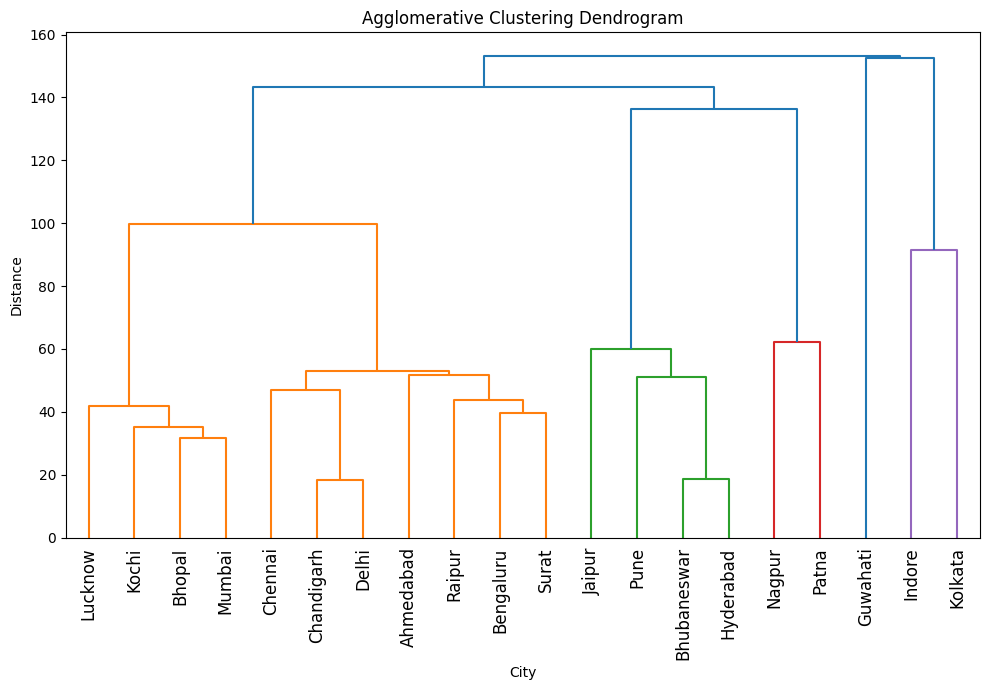

In [ ]:
price = ['Unit_Price_INR', 'Discount', 'Sales_INR', 'Discount_Amount_INR', 'Net_Sales_INR', 'Cost_INR']

# Group the DataFrame by 'City' and compute the mean of the selected numeric columns
city_data = df.groupby('City')[price].mean()

# Perform hierarchical clustering on the numeric city profiles
c = linkage(city_data, method='single')

# Plot the dendrogram
plt.figure(figsize=(10, 7))
dendrogram(c, labels=city_data.index, leaf_rotation=90)
plt.title("Agglomerative Clustering Dendrogram")
plt.xlabel("City")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()

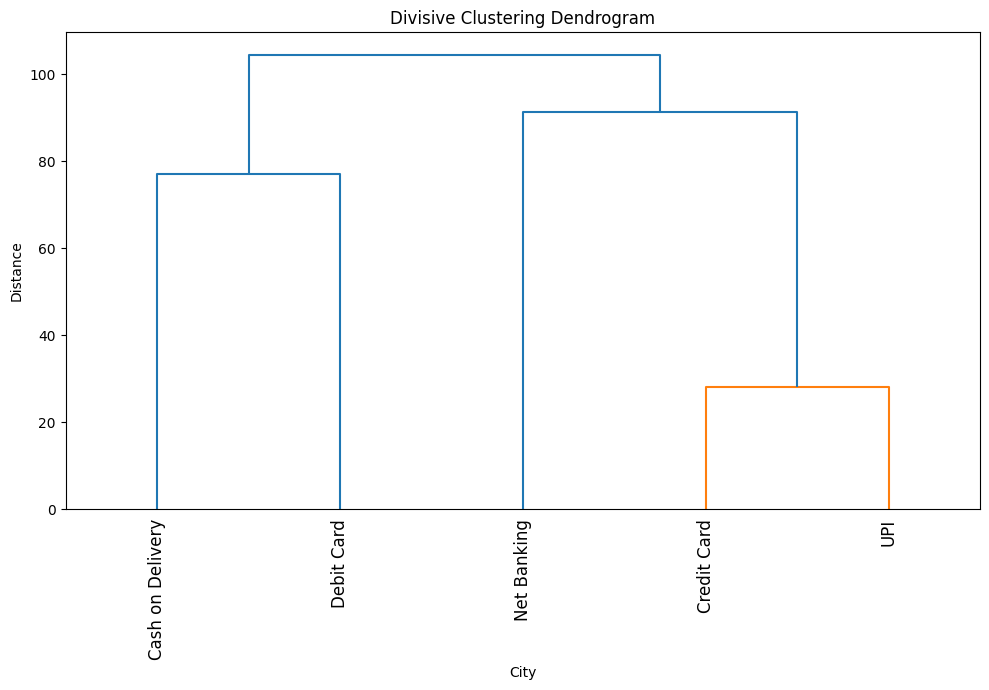

In [28]:
from scipy.cluster.hierarchy import linkage,dendrogram

import matplotlib.pyplot as plt


price = ['Unit_Price_INR', 'Discount', 'Sales_INR', 'Discount_Amount_INR', 'Net_Sales_INR', 'Cost_INR']

# Group the DataFrame by 'City' and compute the mean of the selected numeric columns
fees_data = df.groupby('Payment_Method')[price].mean()

# Perform hierarchical clustering on the numeric city profiles
c = linkage(fees_data, method='single')

# Plot the dendrogram
plt.figure(figsize=(10, 7))
dendrogram(c, labels=fees_data.index, leaf_rotation=90)
plt.title("Divisive Clustering Dendrogram")
plt.xlabel("City")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()